# Resonantly phase-matched 4WM JTWPA (QPDK JosephsonCircuits notebook, twpa-sim `jtwpa4wm`), rebuilt in the Quantcore PDK

**What it is.** A Josephson travelling-wave parametric amplifier: a transmission line made of a long series chain
of junctions with capacitance to ground. A strong pump raises the junction inductance (Kerr), the signal at f_s
mixes with the pump into an idler at 2 f_p − f_s and grows along the line (four-wave mixing). The Kerr shift
leaves the uniform chain phase-mismatched; LC resonators on every few cells, tuned just above the pump, restore
the phase matching (O'Brien et al., PRL 113, 157001 (2014); Macklin et al., Science 350, 307 (2015)).

**Sources.**
* Circuit: QPDK notebook `josephsoncircuits_twpa` (MIT; the JosephsonCircuits.jl example of Peng et al. 2022): 2047
  junctions, I_c 3.4 µA, C_J 55 fF, C_g 45 fF per cell (halved at the ends); every 4th cell 30 fF of C_g becomes a
  30 fF coupling capacitor to a 2.8153 pF ∥ 170 pH resonator (7.275 GHz); pump 3.7 µA peak Norton (≈ 1.85 µA in
  the chain) at 7.12 GHz; reported ≈ 25 dB (loaded) vs ≈ 5 dB (uniform) at 5 GHz.
* Layout family: twpa-sim `jtwpa4wm` (MIT): a series JJ chain with shunt capacitors, half shunts at both ends,
  60 µm cell pitch (`examples/layout/jtwpa4wm.json`, 8 cells).

Both cloned read-only into `build/external/` (never run).

| | source | Quantcore rebuild (why) |
|---|---|---|
| chain | 2047 cells (circuit) / 8 cells (twpa-sim layout) | a **shortened** 64-cell chain on the die (`JtwpaChain`, unit cell parameterised); the full 2047-cell circuit stays in the analysis |
| junction | I_c 3.4 µA, C_J 55 fF | the **largest PDK trilayer junction** (2 × 2 µm, I_c 0.65 µA, L_J 0.51 nH, C_J 200 fF); flagged `pdk_rn`; both the drawn and the source values are simulated |
| shunt C_g | 45 fF (MIM in twpa-sim) | interdigital fingers island–ground per cell (analytic estimate) |
| resonators | 2.8 pF ∥ 170 pH every 4th cell (lumped, ideal) | a pad + meander inductor + coupling IDC beyond the trench wall, every 4th node, alternating sides (drawn values are much smaller: tabulated) |
| chip | — | 7.5 × 7.5 mm PDK die, input / output `BondPad`s 100 µm from the edge |

## 1 · Setup and the PDK

In [2]:
import os, sys
from pathlib import Path
import numpy as np
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
os.chdir(ROOT)
sys.path.insert(0, str(ROOT / "examples" / "designs"))
sys.path.insert(0, str(ROOT / "examples" / "designs" / "amplifiers"))
from _common import *
from _amplifiers import pdk_facts_md, plot, show_md, table_md, lom_sparams
from quantcore_circuits.designer import Designer
from quantcore_circuits.pdk import get_pdk
from quantcore_circuits.analysis import amplifiers as amp
from quantcore_circuits.layouts.others.amplifiers import JtwpaChain, drawn_junction_values
from quantcore_circuits.circuit.bridges import rn_from_lj

LIVE = os.environ.get("QCC_LIVE", "1") == "1"
RUN_FEM = False
OUT = Path("examples/designs/amplifiers")
PDK = get_pdk()
show_md(pdk_facts_md(PDK))

| PDK | value |
|---|---|
| substrate | sapphire 650 µm, εr 10.25 |
| film | Nb 200 nm, λ_L 90 nm → L_s 0.116 pH/□ (kinetic, in every CPW / wire formula) |
| junction rule | Nb/AlOx/Nb trilayer, Δ 1.4 meV, J_c 0.163 µA/µm², R_n window 40–50 kΩ, fingers 0.1–2 µm |
| frame | die 7.5 × 7.5 mm standard, margin 100 µm, marker areas 500 µm, brand QCT |
| pad rule | outer etch 100 µm (one dicing-marker width) from the die edge (`edge="auto"`) |
| cheese | PDK band 3 rows of 5 µm squares, 20 µm gap, around the 3/0 keep-outs (unless the original has its own) |
| 3/0 keep-out | routes + 10 µm, components + 24 µm |

In [3]:
BIG_JJ = {"finger_width": 2.0, "second_finger_width": 2.0}
LJ, CJ, _ = drawn_junction_values("Quantcore Junction", BIG_JJ)
SRC = dict(ic=3.4e-6, cj=55e-15, cg=45e-15, cc=30e-15, lr=170e-12, cr=2.8153e-12, cells=2047, every=4,
           fp=7.12e9, ip=3.7e-6 / 2)
show_md(table_md(["junction", "I_c (µA)", "L_J (pH)", "C_J (fF)", "R_n (kΩ)", "plasma f (GHz)"], [
    ["drawn: trilayer 2.0 × 2.0 µm", amp.ic_from_lj(LJ * 1e-9) * 1e6, LJ * 1e3, CJ, rn_from_lj(LJ) / 1e3,
     1 / (2 * np.pi * np.sqrt(LJ * 1e-9 * CJ * 1e-15)) / 1e9],
    ["QPDK / JosephsonCircuits", 3.4, amp.lj_from_ic(SRC["ic"]) * 1e12, 55, rn_from_lj(amp.lj_from_ic(SRC["ic"]) * 1e9)
     / 1e3, 1 / (2 * np.pi * np.sqrt(amp.lj_from_ic(SRC["ic"]) * SRC["cj"])) / 1e9]]))

| junction | I_c (µA) | L_J (pH) | C_J (fF) | R_n (kΩ) | plasma f (GHz) |
|---|---|---|---|---|---|
| drawn: trilayer 2.0 × 2.0 µm | 0.6516 | 505.1 | 200 | 3.375 | 15.84 |
| QPDK / JosephsonCircuits | 3.4 | 96.8 | 55 | 0.6468 | 68.98 |

## 2 · The die and frame

In [4]:
W = H = 7500
YC = 3750
d = Designer("jtwpa_4wm", box=(0, 0, W, H), chip={"name_chip": "JTWPA"}, live=LIVE)

## 3 · Pads (the 100 µm rule)
Input pad on the west edge, output pad on the east edge (`edge="auto"`).

In [5]:
with d.batch():
    d.add("P_IN", "BondPad", at=(400, YC), rot=-90, edge="auto")
    d.add("P_OUT", "BondPad", at=(7100, YC), rot=90, edge="auto")

## 4 · Components
`JT` (`JtwpaChain`): 64 junctions at 60 µm pitch between 20 µm-wide islands cut by 12 µm gaps, each gap bridged by
the trilayer junction (window 18 × 12 µm). Each full island has 4 shunt fingers per side (40 µm long, 2/2 µm),
interleaved with ground fingers from the trench walls (the end islands half as many: the half shunts). Every 4th
node (2, 6, 10, …) gets a resonator beyond the trench wall, alternating up and down: a lead through a slot in the
10 µm wall, a 10-finger coupling IDC, a 160 × 120 µm pad, a 10-turn meander inductor to the pocket ceiling.

In [6]:
CHAIN = dict(cells=64, cell_pitch=60, junction_params=BIG_JJ, resonator_every=4, resonator_offset=2)
with d.batch():
    jt = d.add("JT", "JtwpaChain", at=(3750 - (2 * 30 + 64 * 60) / 2, YC), junction={"Lj_nH": LJ, "Cj_fF": CJ},
               **CHAIN)
V = JtwpaChain.qcc_values(jt.spec["params"])
f_rd = 1 / (2 * np.pi * np.sqrt(V["Lr_nH"] * 1e-9 * (V["Cr_fF"] + V["Cc_fF"]) * 1e-15)) / 1e9
show_md(table_md(["per cell", "drawn (analytic)", "source"], [
    ["L_J (pH)", LJ * 1e3, amp.lj_from_ic(SRC["ic"]) * 1e12], ["C_J (fF)", CJ, 55],
    ["C_g (fF)", V["Cg_fF"], 45], ["C_g on a loaded node (fF)", V["Cg_loaded_fF"], 15],
    ["C_c (fF)", V["Cc_fF"], 30], ["C_r (fF)", V["Cr_fF"], 2815.3],
    ["L_r (nH, incl. kinetic)", V["Lr_nH"], 0.170], ["resonator f (GHz)", f_rd, 7.275],
    ["Z = √(L_J/C_g) (Ω)", np.sqrt(LJ * 1e-9 / (V["Cg_fF"] * 1e-15)), np.sqrt(amp.lj_from_ic(SRC["ic"]) / SRC["cg"])]]))

| per cell | drawn (analytic) | source |
|---|---|---|
| L_J (pH) | 505.1 | 96.8 |
| C_J (fF) | 200 | 55 |
| C_g (fF) | 31.95 | 45 |
| C_g on a loaded node (fF) | 15.97 | 15 |
| C_c (fF) | 17.87 | 30 |
| C_r (fF) | 72.18 | 2815 |
| L_r (nH, incl. kinetic) | 2.769 | 0.17 |
| resonator f (GHz) | 10.08 | 7.275 |
| Z = √(L_J/C_g) (Ω) | 125.7 | 46.38 |

## 5 · Routes
Straight 50 Ω feeds from the pads to the chain ports.

In [7]:
with d.batch():
    d.route("L_IN", "P_IN.a", "JT.a")
    d.route("L_OUT", "JT.b", "P_OUT.a")
d.sim_group("chain", ["JT"], margin_um=60, analyses=["q3d_cmatrix"])
if not LIVE:
    d.show()
DESIGN = d.save(OUT / "jtwpa_4wm.json")
print(d, "→", DESIGN)

<Designer jtwpa_4wm: 3 instances, 2 routes, live=False> → examples\designs\amplifiers\jtwpa_4wm.json


## 6 · DRC
`pdk_rn` flags the chain junction (R_n ≈ 3.4 kΩ): a TWPA junction must be large.

In [8]:
print(d.drc())
show_md(pdk_report(d))

DRC clean (1 PDK design warning(s))
design  pdk_rn        JT: junction R_n 3.4 kΩ is outside the PDK window 40–50 kΩ (L_J 0.50508 nH)


| check | value |
|---|---|
| cheese | PDK band (drawn in the build) |
| content centre − die centre | (+0, +0) µm |
| junction types | Quantcore Junction × 1 |
| PDK design warnings | 1 (pdk_rn × 1) |
| pdk_rn | JT: junction R_n 3.4 kΩ is outside the PDK window 40–50 kΩ (L_J 0.50508 nH) |

## 7 · Netlist and LOM
`JtwpaChain`'s model: 65 island nodes `JT.n0` … `JT.n64` (n0 / n64 joined to the pads by the feeds), a JJ between
neighbours, C_g to ground on each node, and per resonator a node `JT.r<k>` with C_c, C_r, L_r. 64 junctions are
far beyond QuCat's normal-mode solver (a few junctions), so the netlist is simulated linearly below.

In [9]:
lb = d.lom()
m = lb.model
show_md(f"**{len(m.nodes) - 1} nodes, {len(m.branches)} branches** "
        f"({sum(b.type == 'JJ' for b in m.branches.values())} JJ, {sum(b.type == 'L' for b in m.branches.values())} L)")
show_md(table_md(["branch", "type", "nodes", "value"], [
    [n, b.type, " – ".join(b.nodes), b.value.get("Lj_nH", b.value.get("L_nH", b.value.get("estimate")))]
    for n, b in list(m.branches.items())[:12]]) + "\n\n… (first 12 branches)")

**81 nodes, 179 branches** (64 JJ, 16 L)

| branch | type | nodes | value |
|---|---|---|---|
| Port_P_IN | R | JT.n0 – gnd | – |
| Port_P_OUT | R | JT.n64 – gnd | – |
| Cg_JT_0 | C | JT.n0 – gnd | 16.8 |
| Cg_JT_1 | C | JT.n1 – gnd | 31.9 |
| Cg_JT_2 | C | JT.n2 – gnd | 16 |
| Cg_JT_3 | C | JT.n3 – gnd | 31.9 |
| Cg_JT_4 | C | JT.n4 – gnd | 31.9 |
| Cg_JT_5 | C | JT.n5 – gnd | 31.9 |
| Cg_JT_6 | C | JT.n6 – gnd | 16 |
| Cg_JT_7 | C | JT.n7 – gnd | 31.9 |
| Cg_JT_8 | C | JT.n8 – gnd | 31.9 |
| Cg_JT_9 | C | JT.n9 – gnd | 31.9 |

… (first 12 branches)

## 8 · LOM simulation
**(a) The drawn chain, linear** (`lom_sparams`: nodal analysis of the LOM netlist, junctions as L_J ∥ C_J):
transmission of the 64-cell die between the 50 Ω pads, and the Bloch dispersion of its 4-cell unit.

~\AppData\Local\Temp\ipykernel_81136\3444727021.py:7: RuntimeWarning: divide by zero encountered in log10
  plot(OUT / "jtwpa_4wm_s21.png", [(f / 1e9, 20 * np.log10(np.abs(S[:, 1, 0])), "|S21| drawn 64-cell chain (LOM)"),


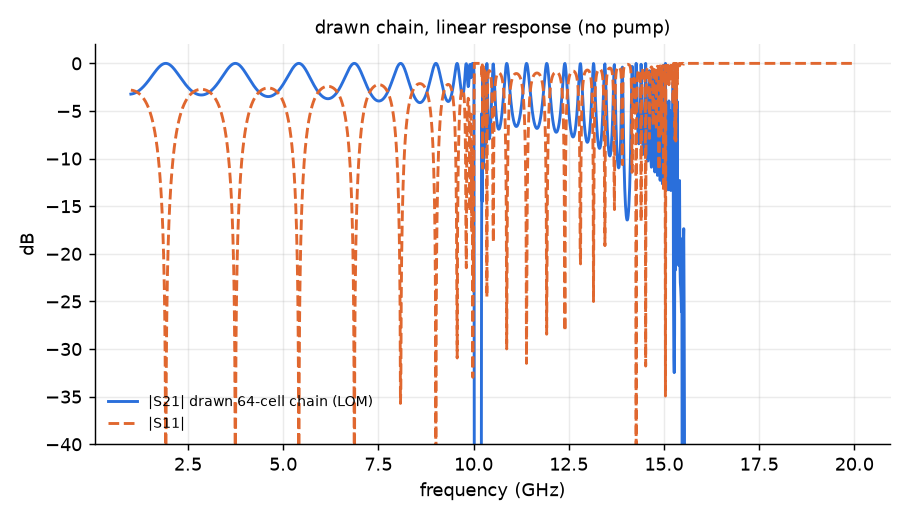

WindowsPath('examples/designs/amplifiers/jtwpa_4wm_s21.png')

In [10]:
f = np.linspace(1e9, 20e9, 1901)
port_nodes = [lb.port_map["P_IN.a"], lb.port_map["P_OUT.a"]]
S = lom_sparams(m, f, port_nodes)
cg, cgl = V["Cg_fF"] * 1e-15, V["Cg_loaded_fF"] * 1e-15
unit_d = amp.jtwpa_unit(f, LJ * 1e-9, CJ * 1e-15, cg, 4, (V["Cc_fF"] * 1e-15, V["Lr_nH"] * 1e-9, V["Cr_fF"] * 1e-15),
                        cgl)
plot(OUT / "jtwpa_4wm_s21.png", [(f / 1e9, 20 * np.log10(np.abs(S[:, 1, 0])), "|S21| drawn 64-cell chain (LOM)"),
                                  (f / 1e9, 20 * np.log10(np.abs(S[:, 0, 0])), "|S11|", "--")],
     "frequency (GHz)", "dB", "drawn chain, linear response (no pump)", ylim=(-40, 2))

**(b) The source circuit, 2047 cells** (QPDK values): Bloch phase per junction of the uniform and the loaded
chain, the cold mismatch 2q_p − q_s − q_i, and the 4WM coupled-mode gain with the pump at 7.12 GHz and
I_p = 1.85 µA ((I_p/I_c)² = 0.296), `analysis.amplifiers.cme_gain` (undepleted pump; ξ = 1/(2 I_c²)).

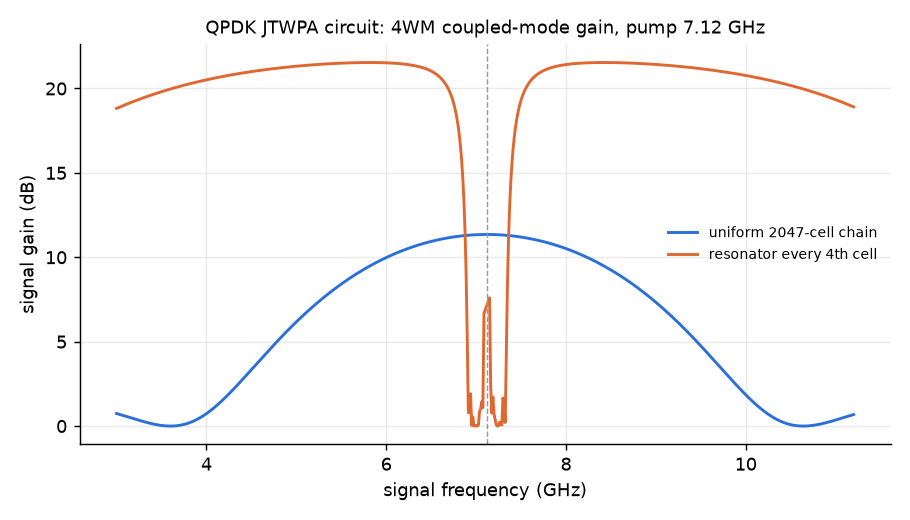

| chain | G at 5 GHz (dB) | Δβ at 5 GHz (rad/junction) | QPDK harmonic balance (dB) |
|---|---|---|---|
| uniform | 6.174 | -0.003777 | ≈ 5 |
| loaded | 21.32 | 0.001488 | ≈ 25 |

In [11]:
lj_s = amp.lj_from_ic(SRC["ic"])
res_s = (SRC["cc"], SRC["lr"], SRC["cr"])

def q_src(freq, loaded):
    u = amp.jtwpa_unit(np.atleast_1d(freq), lj_s, SRC["cj"], SRC["cg"], 4 if loaded else 0,
                       res_s if loaded else None, SRC["cg"] - SRC["cc"])
    return amp.bloch(u).imag / (4 if loaded else 1)

fs = np.linspace(3e9, 11.2e9, 661)
fs = fs[np.abs(fs - SRC["fp"]) > 0.02e9]
GAIN = {}
for loaded in (False, True):
    kp = float(q_src(SRC["fp"], loaded)[0])
    g, dbeta, _ = amp.cme_gain(q_src(fs, loaded), q_src(2 * SRC["fp"] - fs, loaded), kp, SRC["cells"], SRC["ip"],
                               xi=1 / (2 * SRC["ic"] ** 2))
    GAIN["loaded" if loaded else "uniform"] = (amp.db(g), dbeta)
plot(OUT / "jtwpa_4wm_gain.png", [(fs / 1e9, GAIN["uniform"][0], "uniform 2047-cell chain"),
                                   (fs / 1e9, GAIN["loaded"][0], "resonator every 4th cell")],
     "signal frequency (GHz)", "signal gain (dB)", "QPDK JTWPA circuit: 4WM coupled-mode gain, pump 7.12 GHz",
     vline=SRC["fp"] / 1e9)
i5 = int(np.argmin(np.abs(fs - 5e9)))
show_md(table_md(["chain", "G at 5 GHz (dB)", "Δβ at 5 GHz (rad/junction)", "QPDK harmonic balance (dB)"], [
    ["uniform", GAIN["uniform"][0][i5], GAIN["uniform"][1][i5], "≈ 5"],
    ["loaded", GAIN["loaded"][0][i5], GAIN["loaded"][1][i5], "≈ 25"]]))

**(c) The drawn unit cell as a TWPA**: the same coupled-mode model with the drawn values, the chain extended to
2047 cells and the pump scaled to the same (I_p/I_c)² = 0.296 (I_p ≈ 0.35 µA). The drawn line is far from 50 Ω
(L_J/C_g, tabulated above) and its resonators sit far from the pump, so it is not phase-matched as drawn: the
numbers say what the PDK cell would need (larger C_g, larger resonator C) rather than predict a device.

In [12]:
ic_d = amp.ic_from_lj(LJ * 1e-9)
def q_drawn(freq):
    return amp.bloch(amp.jtwpa_unit(np.atleast_1d(freq), LJ * 1e-9, CJ * 1e-15, cg, 4,
                                    (V["Cc_fF"] * 1e-15, V["Lr_nH"] * 1e-9, V["Cr_fF"] * 1e-15), cgl)).imag / 4
kp = float(q_drawn(SRC["fp"])[0])
gd, _, _g = amp.cme_gain(q_drawn(fs), q_drawn(2 * SRC["fp"] - fs), kp, 2047, np.sqrt(0.296) * ic_d,
                        xi=1 / (2 * ic_d**2))
show_md(f"Drawn cell: q_p = {kp:.3f} rad/junction at 7.12 GHz (source {float(q_src(SRC['fp'], True)[0]):.3f}); "
        f"G at 5 GHz ≈ {amp.db(gd)[i5]:.1f} dB for 2047 cells (Δβ = {float(_[i5]):+.4f} rad/junction: not phase "
        "matched; spikes in G next to the drawn resonator's stop band are outside this model's validity).")

Drawn cell: q_p = 0.206 rad/junction at 7.12 GHz (source 0.096); G at 5 GHz ≈ 0.1 dB for 2047 cells (Δβ = -0.0428 rad/junction: not phase matched; spikes in G next to the drawn resonator's stop band are outside this model's validity).

## 9 · FEM: send the jobs
A Q3D C-matrix job of the whole drawn chain (65 islands, 16 resonator pads: it replaces the C_g, C_c, C_r
estimates; the junctions are drawn as `Sim` gaps). Export only (`RUN_FEM = False`).

In [13]:
jobs = export_sims(DESIGN, ["chain"])
display(Markdown(jobs_md(jobs)))
if RUN_FEM:
    from quantcore_circuits.sim_tools import solve_job
    solve_job(jobs["chain"][0])

| group | job | ports (number · kind · name) | C-matrix nets |
|---|---|---|---|
| chain | `build/jobs/jtwpa_4wm_chain_q3d_cmatrix` | 1 · edge · `L_IN`<br>2 · edge · `L_OUT` | `L_IN`, `L_OUT`, `JT.n1`, `JT.n3`, `JT.n4`, `JT.n5`, `JT.n6`, `JT.n7`, `JT.n8`, `JT.n9`, `JT.n11`, `JT.n12`, `JT.n13`, `JT.n14`, `JT.n15`, `JT.n16`, `JT.n17`, `JT.n19`, `JT.n20`, `JT.n21`, `JT.n22`, `JT.n23`, `JT.n24`, `JT.n25`, `JT.n27`, `JT.n28`, `JT.n29`, `JT.n30`, `JT.n31`, `JT.n32`, `JT.n33`, `JT.n35`, `JT.n36`, `JT.n37`, `JT.n38`, `JT.n39`, `JT.n40`, `JT.n41`, `JT.n43`, `JT.n44`, `JT.n45`, `JT.n46`, `JT.n47`, `JT.n48`, `JT.n49`, `JT.n51`, `JT.n52`, `JT.n53`, `JT.n54`, `JT.n55`, `JT.n56`, `JT.n57`, `JT.n59`, `JT.n60`, `JT.n61`, `JT.n62`, `JT.n63`, `JT.n2`, `JT.n10`, `JT.n18`, `JT.n26`, `JT.n34`, `JT.n42`, `JT.n50`, `JT.n58` |

## 10 · Bring it back

In [14]:
job = jobs["chain"][0]
show_md("C-matrix found: `fill(lb.model, d.design, job)`, then re-run 8 (a)" if (Path(job) / "results" /
        "results.json").exists() else f"No results in `{job}` yet: C_g, C_c, C_r are analytic estimates.")

No results in `build\jobs\jtwpa_4wm_chain_q3d_cmatrix` yet: C_g, C_c, C_r are analytic estimates.

## 11 · Iterate: the loading resonator
One property: the meander inductor 10 → 20 turns (longer wire: larger L_r, lower resonator frequency).

| turns | wire (µm) | L_r (nH) | kinetic (pH) | f_r (GHz) |
|---|---|---|---|---|
| 10 | 1702 | 2.769 | 98.53 | 10.08 |
| 20 | 3282 | 5.77 | 190 | 6.982 |

~\AppData\Local\Temp\ipykernel_81136\771605567.py:11: RuntimeWarning: divide by zero encountered in log10
  plot(OUT / "jtwpa_4wm_iterate.png", [(f / 1e9, 20 * np.log10(np.abs(S[:, 1, 0])), "10 turns"),


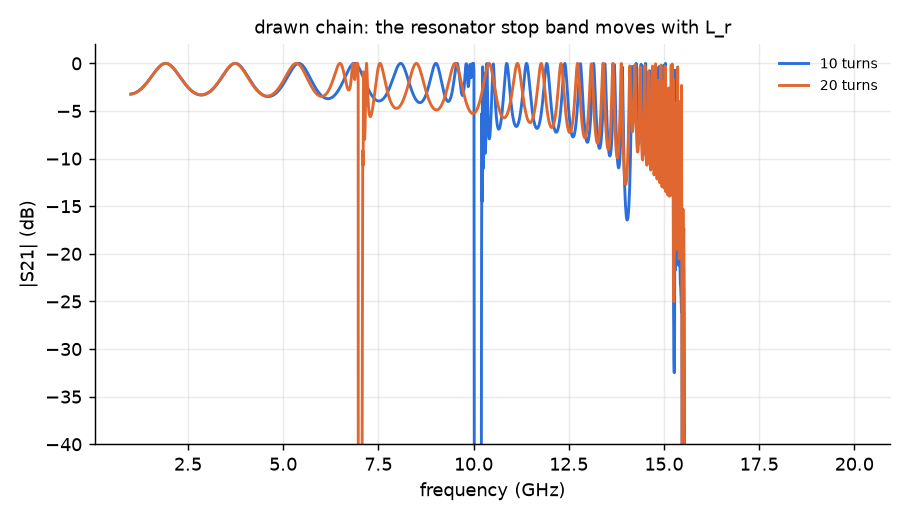

WindowsPath('examples/designs/amplifiers/jtwpa_4wm_iterate.png')

In [15]:
V20 = JtwpaChain.qcc_values({**jt.spec["params"], "inductor_turns": 20})
rows = []
for turns, v in ((10, V), (20, V20)):
    rows.append([turns, v["inductor_length_um"], v["Lr_nH"], 1e3 * v["Lr_k_nH"],
                 1 / (2 * np.pi * np.sqrt(v["Lr_nH"] * 1e-9 * (v["Cr_fF"] + v["Cc_fF"]) * 1e-15)) / 1e9])
show_md(table_md(["turns", "wire (µm)", "L_r (nH)", "kinetic (pH)", "f_r (GHz)"], rows))
d["JT"].set(inductor_turns=20)
S20 = lom_sparams(d.lom().model, f, port_nodes)
d["JT"].set(inductor_turns=10)
DESIGN = d.save(OUT / "jtwpa_4wm.json")
plot(OUT / "jtwpa_4wm_iterate.png", [(f / 1e9, 20 * np.log10(np.abs(S[:, 1, 0])), "10 turns"),
                                      (f / 1e9, 20 * np.log10(np.abs(S20[:, 1, 0])), "20 turns")],
     "frequency (GHz)", "|S21| (dB)", "drawn chain: the resonator stop band moves with L_r", ylim=(-40, 2))

## 12 · Build and export
`qcc build examples/designs/amplifiers/jtwpa_4wm.json`, `qcc mask …`.

In [16]:
from quantcore_circuits.layouts.wafers.fab_export import export_fab
if d.result is None:
    d.show()
fab = {}
export_fab(d.result, Path("build") / f"{d.design.name}_fab.oas", report=fab)
show_md(f"cheese: {fab.get('cheese_source')}; written: " + ", ".join(f"{k} {n}" for k, n in fab["written"].items()))

cheese: build; written: M1 1825, JJ_STRAIGHT 64, M3 1825, JJ_BENT 64, HSQ 128, SPACER_1 128, SPACER_2 128, SPACER_3 128, CHIP_BOUNDARY 1, MARKERS_DICING 4, MARKERS_ALIGN 36

## 13 · Snapshots
The full die; one loaded unit (four cells and a resonator); one junction (trilayer window in the island cut).

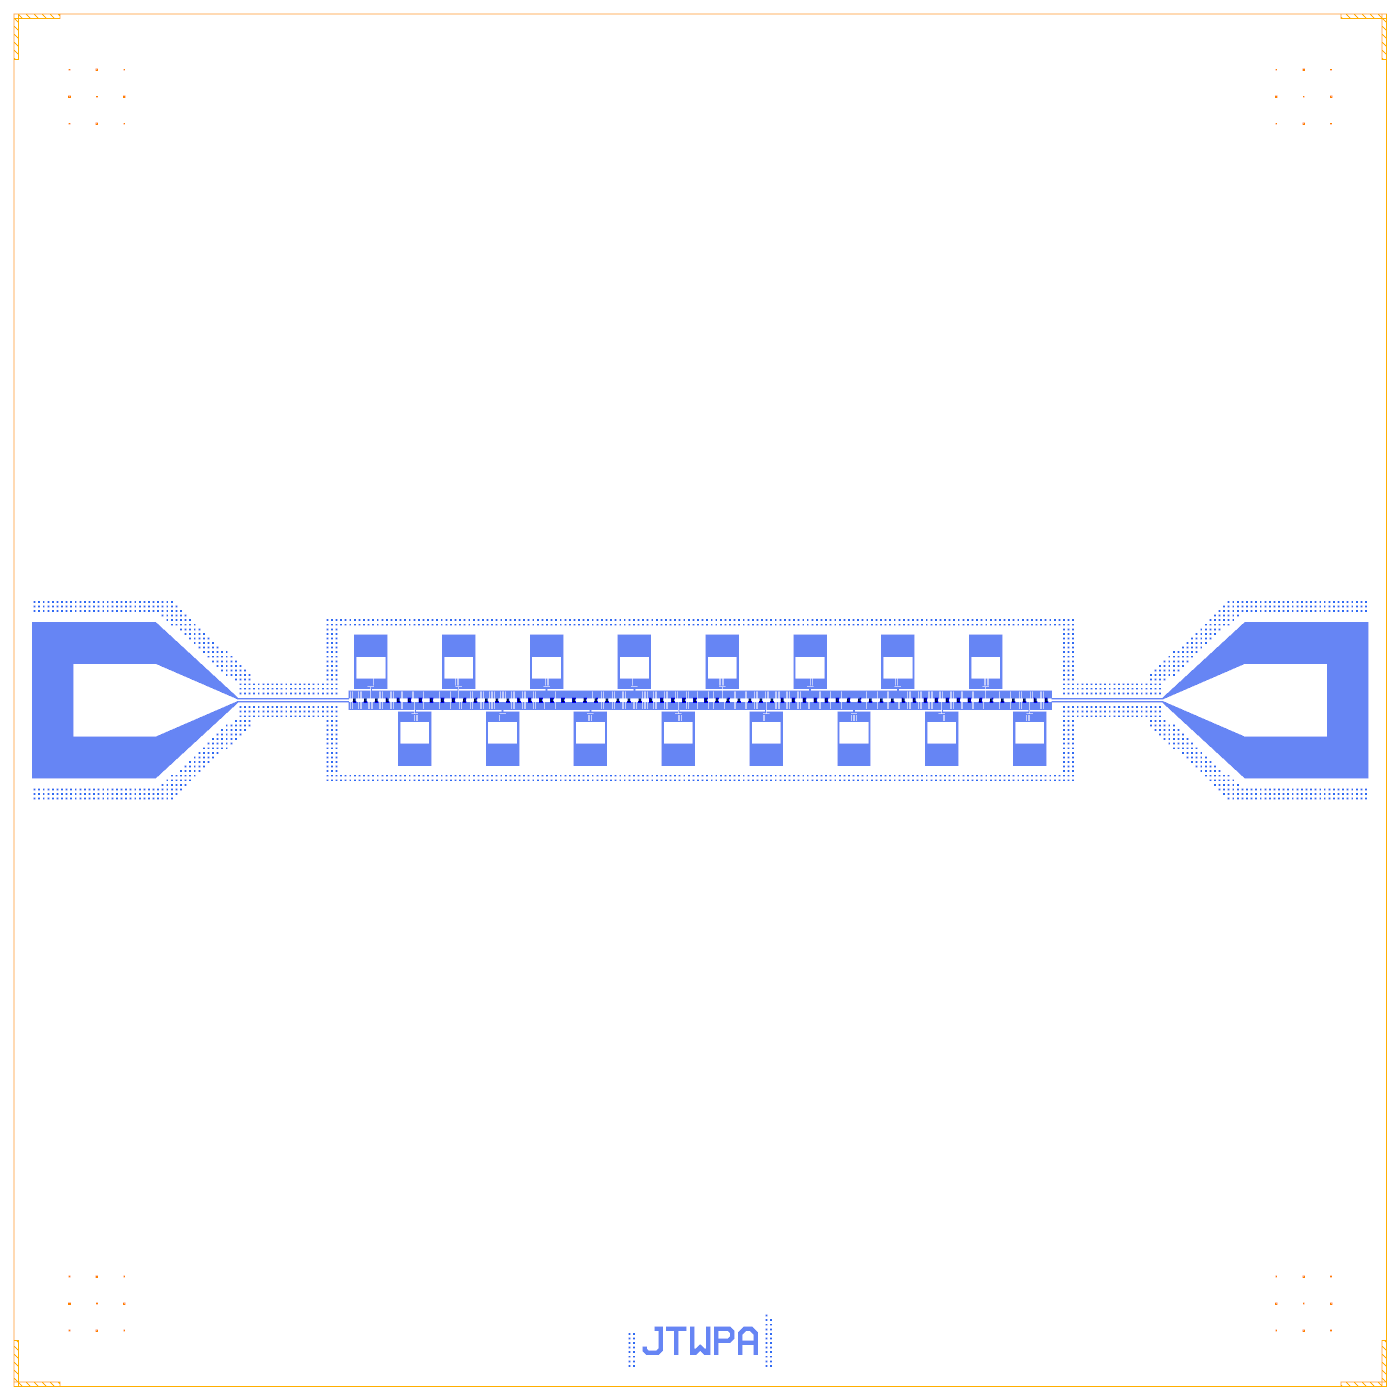

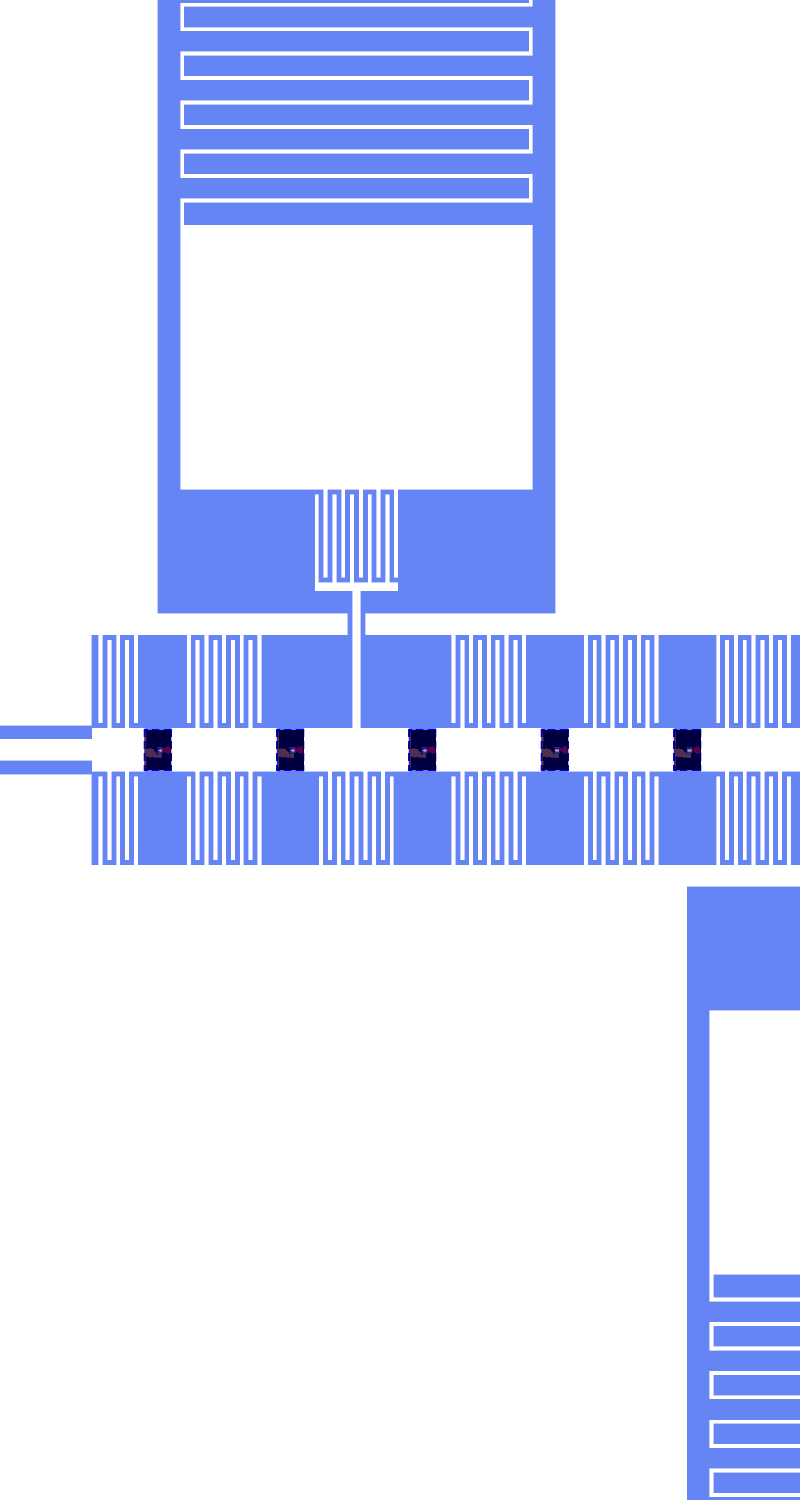

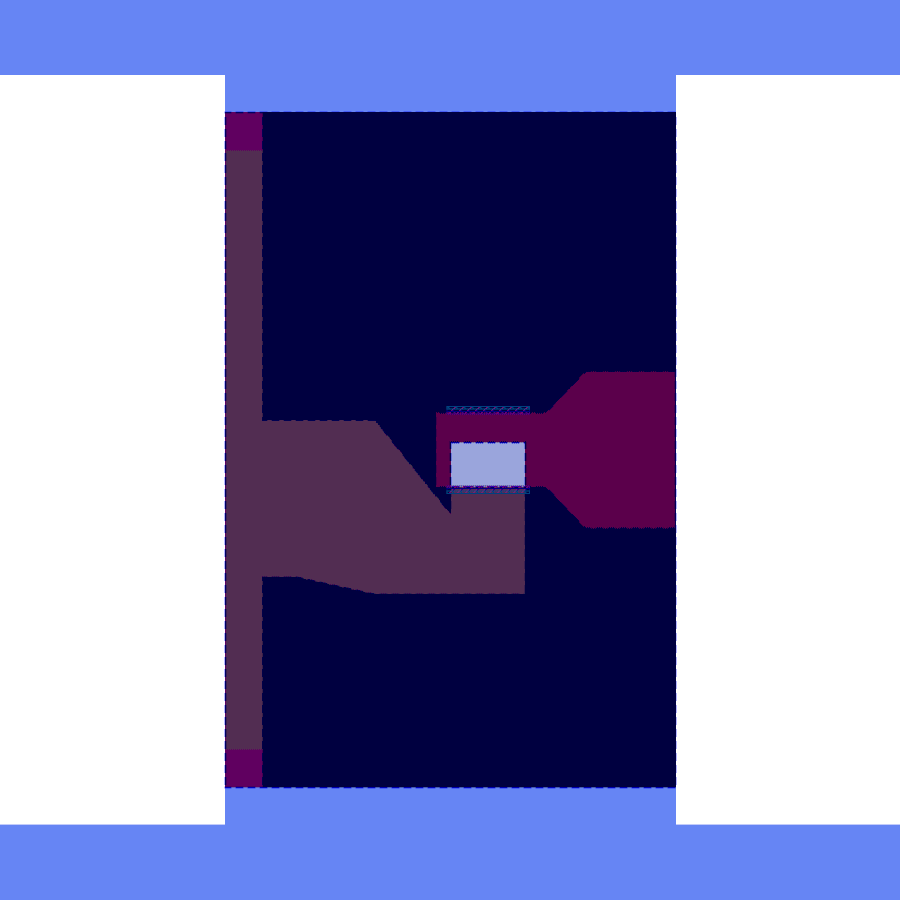

WindowsPath('examples/designs/amplifiers/jtwpa_4wm_jj.png')

In [17]:
show_snapshot(d, OUT / "jtwpa_4wm.png", size=(1400, 1400))
x0, y0 = port_xy(d, "JT.a")
show_snapshot(d, OUT / "jtwpa_4wm_unit.png", box=(x0 + 20, y0 - 340, x0 + 320, y0 + 340), size=(800, 1500),
              width=360)
xj = x0 + 30 + 1.5 * 60
show_snapshot(d, OUT / "jtwpa_4wm_jj.png", box=(xj - 12, y0 - 12, xj + 12, y0 + 12), size=(900, 900), width=360)

## 14 · Summary
* **Matches the source:** a series junction chain with shunt capacitors and half shunts at both ends (twpa-sim),
  resonators on every 4th cell (QPDK / O'Brien); the 2047-cell source circuit is simulated (dispersion, cold
  mismatch, gain) and reproduces QPDK's trend (loaded ≫ uniform at 5 GHz).
* **Differs:** a 64-cell chain on the die; the PDK junction (0.65 µA, L_J 0.51 nH) instead of 3.4 µA; planar shunt
  and resonator capacitors whose drawn values (tabulated) are far below the source's 45 fF / 2.8 pF.
* **PDK design warnings:** `pdk_rn` on `JT`.
* **Open:** a PDK-native JTWPA needs C_g ≈ L_J/Z0² ≈ 0.2 pF per cell and pF-scale resonators (or a higher-J_c
  junction process, a PDK request); harmonic balance (JosephsonCircuits.jl) is not
  in this environment.